# EDA de Goodreads: poesía y cómics

## Objetivo, alcance y unidad de análisis
Este notebook sigue el ciclo de inventario, calidad, estadística descriptiva, visualización, outliers e interpretación usado como referencia metodológica en el laboratorio ShapeNet. La unidad de catálogo es la edición (`book_id`) y la de interacción es una fila auditable; un mismo `review_id` contradictorio no se elimina. Los resultados describen Goodreads y no disponibilidad de la biblioteca.

In [1]:
from pathlib import Path
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

sns.set_theme(style='whitegrid', context='notebook')
ROOT = Path.cwd().resolve()
if not (ROOT / 'data' / 'processed').exists(): ROOT = ROOT.parent
PROCESSED, REPORTS = ROOT / 'data' / 'processed', ROOT / 'data' / 'reports'
FIGURES = REPORTS / 'figures'; FIGURES.mkdir(parents=True, exist_ok=True)
if not (PROCESSED / 'books.parquet').exists():
    raise FileNotFoundError('Ejecute primero src/data/build_dataset.py')
con = duckdb.connect()
def q(sql): return con.execute(sql).df()
def savefig(name):
    plt.tight_layout(); plt.savefig(FIGURES / name, dpi=160, bbox_inches='tight'); plt.show()
books = PROCESSED / 'books.parquet'; interactions = PROCESSED / 'interactions.parquet'
sources = PROCESSED / 'book_source_genres.parquet'; interaction_sources = PROCESSED / 'interaction_source_genres.parquet'
authors = PROCESSED / 'book_authors.parquet'; audit = PROCESSED / 'duplicate_audit.parquet'


## 1. Inventario, integridad y duplicados
Objetivo: cuantificar la consolidación sin ocultar conflictos. Una réplica se elimina solo si comparte `review_id` y los campos `user_id`, `book_id`, `is_read`, `rating`, `date_added`, `date_updated`, `read_at` y `started_at`; las variantes contradictorias permanecen en `interactions.parquet` y se registran en la auditoría. `metadata_conflicts.csv` compara únicamente `work_id` y `title` entre fuentes de un mismo `book_id`; no certifica igualdad de todos los metadatos bibliográficos.

In [2]:
quality = pd.read_csv(REPORTS / 'quality_summary.csv')
display(quality)
audit_summary = q(f"SELECT duplicate_class, count(*) AS grupos, sum(source_rows) AS filas FROM read_parquet('{audit}') GROUP BY 1 ORDER BY 1")
display(audit_summary)
book_count = int(q(f"SELECT count(*) AS n FROM read_parquet('{books}')").loc[0, 'n'])
conflicts = int(audit_summary.loc[audit_summary['duplicate_class'].eq('conflicting_review_id'), 'grupos'].sum())
display(Markdown(f"**Interpretación.** Se consolidaron **{book_count:,}** ediciones. Hay **{conflicts:,}** grupos de `review_id` contradictorio: no se usan para reducir filas, porque podrían reflejar una revisión inconsistente o una exportación divergente. Cualquier filtrado futuro debe partir de esta auditoría."))


,metric,value
0,books_input_rows,125925
1,books_unique,125871
2,books_with_description,103068
3,books_with_language,76817
4,books_with_authors,125871
5,book_metadata_conflicts,0
6,interactions_input_rows,10081980
7,interactions_output_rows,10075726
8,interactions_exact_duplicate_rows_deduplicated,6254
9,review_id_conflict_groups,0


,duplicate_class,grupos,filas
0,exact_duplicate,6254,12508.0


**Interpretación.** Se consolidaron **125,871** ediciones. Hay **0** grupos de `review_id` contradictorio: no se usan para reducir filas, porque podrían reflejar una revisión inconsistente o una exportación divergente. Cualquier filtrado futuro debe partir de esta auditoría.

## 3. Etiquetas de género Goodreads
Objetivo: comparar las etiquetas aproximadas derivadas de estanterías, sus pesos y su distribución entre subconjuntos. No constituyen una taxonomía editorial ni deben confundirse con el origen `poetry` o `comics_graphic`.

,source_genre,genre,libros,peso_medio,rango
0,comics_graphic,"comics, graphic",89411,205.23,1
1,comics_graphic,fiction,60066,27.44,2
2,comics_graphic,"fantasy, paranormal",42110,42.78,3
3,comics_graphic,young-adult,27687,15.03,4
4,comics_graphic,"mystery, thriller, crime",21695,12.47,5
5,comics_graphic,romance,17450,14.31,6
6,comics_graphic,"history, historical fiction, biography",15254,31.80,7
7,comics_graphic,children,11968,19.76,8
8,comics_graphic,non-fiction,9170,56.68,9
9,comics_graphic,poetry,847,7.03,10


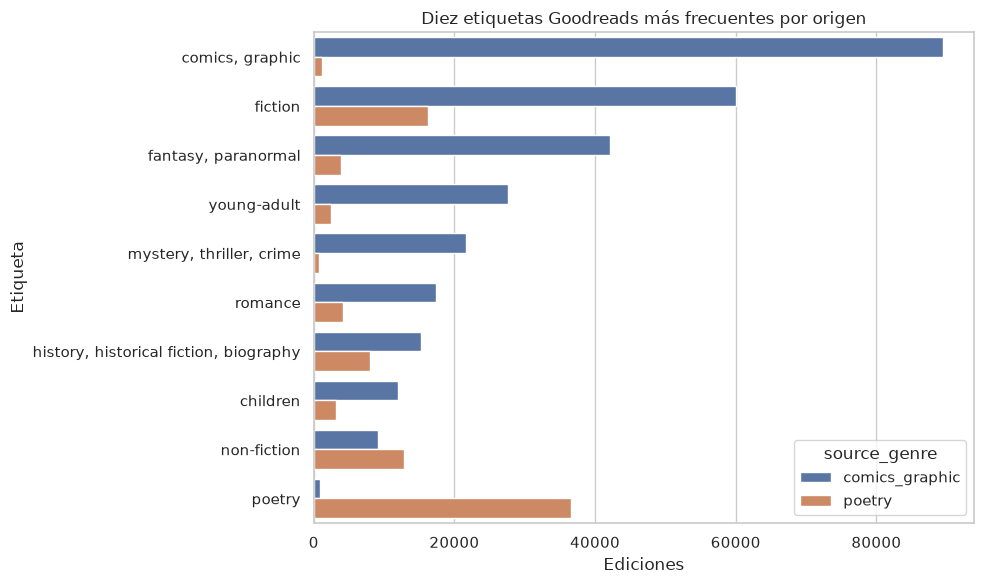

**Interpretación.** Las diferencias observadas describen etiquetas comunitarias y su peso agregado. Para contenido futuro convendrá medir cobertura y solapamiento, pero no usar estos conteos globales como una señal de entrenamiento sin recalcularlos dentro de cada partición.

In [3]:
genre_by_source = q(f"""WITH grouped AS (
  SELECT s.source_genre, g.genre, count(DISTINCT g.book_id) AS libros, avg(g.genre_weight) AS peso_medio
  FROM read_parquet('{sources}') s JOIN read_parquet('{PROCESSED / 'book_genres.parquet'}') g USING(book_id)
  GROUP BY 1, 2
), ranked AS (SELECT *, row_number() OVER (PARTITION BY source_genre ORDER BY libros DESC, genre) AS rango FROM grouped)
SELECT * FROM ranked WHERE rango <= 10 ORDER BY source_genre, rango""")
display(genre_by_source.round({'peso_medio': 2}))
plt.figure(figsize=(10, 6)); sns.barplot(data=genre_by_source, y='genre', x='libros', hue='source_genre')
plt.title('Diez etiquetas Goodreads más frecuentes por origen'); plt.xlabel('Ediciones'); plt.ylabel('Etiqueta'); savefig('03_goodreads_genres_by_source.png')
display(Markdown('**Interpretación.** Las diferencias observadas describen etiquetas comunitarias y su peso agregado. Para contenido futuro convendrá medir cobertura y solapamiento, pero no usar estos conteos globales como una señal de entrenamiento sin recalcularlos dentro de cada partición.'))

## 2. Calidad del catálogo y cobertura de metadatos
Objetivo: medir los campos disponibles sobre libros únicos. La cobertura no se calcula tras unir autores, ya que un libro con varios autores multiplicaría artificialmente su peso. La tabla por género de origen conserva libros compartidos en ambos subconjuntos.

,pct_descripcion,pct_idioma
0,81.88,61.03


,source_genre,libros,pct_descripcion,pct_idioma
0,comics_graphic,89411,82.90,66.88
1,poetry,36514,79.39,46.70


,idioma,libros,pct_descripcion
0,Sin código,49054,74.87
1,eng,37895,88.67
2,spa,4790,90.67
3,fre,4457,81.33
4,ind,4187,76.00
5,en-US,3830,88.93
6,jpn,3639,84.20
7,ita,3089,92.07
8,ger,1780,85.39
9,ara,1743,74.07


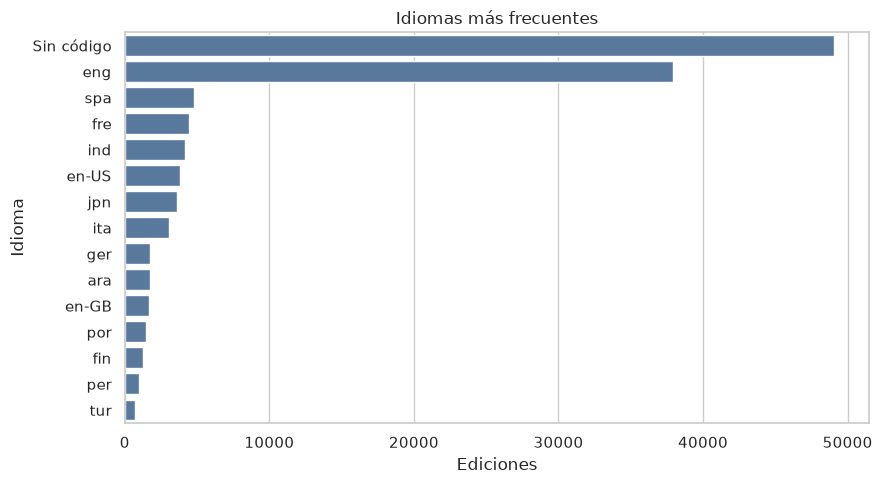

**Interpretación.** La cobertura global correcta es **81.9%** para descripción y **61.0%** para idioma. Los faltantes deben conservarse: un método futuro basado en contenido necesitará rutas alternativas para esas ediciones, no una eliminación ciega.

In [4]:
coverage = q(f"""SELECT
  100.0 * avg((description IS NOT NULL AND trim(description) <> '')::INT) AS pct_descripcion,
  100.0 * avg((language_code IS NOT NULL AND trim(language_code) <> '')::INT) AS pct_idioma
FROM read_parquet('{books}')""")
coverage_by_source = q(f"""SELECT s.source_genre, count(DISTINCT b.book_id) AS libros,
  round(100.0 * avg((b.description IS NOT NULL AND trim(b.description) <> '')::INT), 2) AS pct_descripcion,
  round(100.0 * avg((b.language_code IS NOT NULL AND trim(b.language_code) <> '')::INT), 2) AS pct_idioma
FROM read_parquet('{sources}') s JOIN read_parquet('{books}') b USING(book_id)
GROUP BY 1 ORDER BY libros DESC""")
coverage_by_language = q(f"""SELECT coalesce(nullif(language_code, ''), 'Sin código') AS idioma, count(*) AS libros,
  round(100.0 * avg((description IS NOT NULL AND trim(description) <> '')::INT), 2) AS pct_descripcion
FROM read_parquet('{books}') GROUP BY 1 HAVING count(*) >= 100 ORDER BY libros DESC LIMIT 15""")
display(coverage.round(2)); display(coverage_by_source); display(coverage_by_language)
languages = q(f"SELECT coalesce(nullif(language_code, ''), 'Sin código') AS idioma, count(*) AS libros FROM read_parquet('{books}') GROUP BY 1 ORDER BY 2 DESC LIMIT 15")
plt.figure(figsize=(9, 5)); sns.barplot(data=languages, y='idioma', x='libros', color='#4c78a8')
plt.title('Idiomas más frecuentes'); plt.xlabel('Ediciones'); plt.ylabel('Idioma'); savefig('02_languages.png')
display(Markdown(f"**Interpretación.** La cobertura global correcta es **{coverage.loc[0, 'pct_descripcion']:.1f}%** para descripción y **{coverage.loc[0, 'pct_idioma']:.1f}%** para idioma. Los faltantes deben conservarse: un método futuro basado en contenido necesitará rutas alternativas para esas ediciones, no una eliminación ciega."))


## 3. Años de publicación y valores atípicos
Objetivo: describir la temporalidad del catálogo sin que años aislados compriman el gráfico, y cuantificar candidatos a outlier con IQR. Los límites son diagnósticos, no reglas de eliminación.

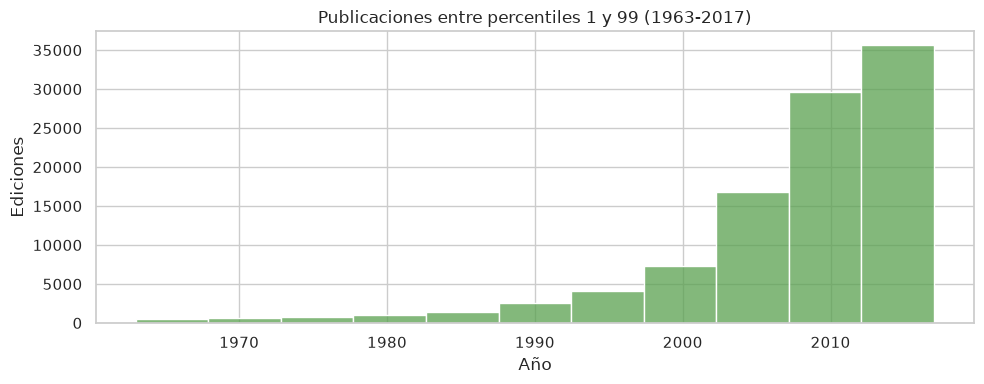

,variable,q1,q3,iqr,limite_superior,posibles_outliers,ejemplos_valor
0,num_pages,95.0,208.0,113.0,377.5,6070,"[{'title': 'الأغاني', 'num_pages': 10960}, {'t..."
1,ratings_count,11.0,111.0,100.0,261.0,17504,"[{'title': 'Where the Sidewalk Ends', 'ratings..."


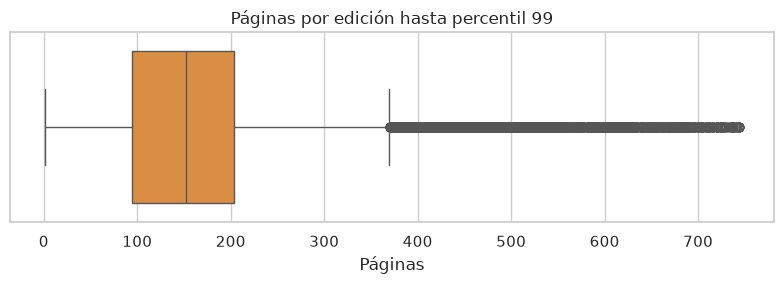

**Interpretación.** El gráfico usa percentiles 1-99 solo para conservar legibilidad; los años extremos permanecen en datos. IQR identifica 6,070 posibles outliers de páginas y debe motivar revisión, no descarte automático.

In [5]:
years = q(f"SELECT publication_year AS anio FROM read_parquet('{books}') WHERE publication_year BETWEEN 1000 AND 2030")
year_low, year_high = years['anio'].quantile([.01, .99]).astype(int)
year_plot = years[years['anio'].between(year_low, year_high)]
plt.figure(figsize=(10, 4)); sns.histplot(year_plot['anio'], binwidth=5, color='#59a14f')
plt.title(f'Publicaciones entre percentiles 1 y 99 ({year_low}-{year_high})'); plt.xlabel('Año'); plt.ylabel('Ediciones'); savefig('04_publication_years.png')
numeric = q(f"SELECT title, num_pages, ratings_count FROM read_parquet('{books}') WHERE num_pages > 0 OR ratings_count >= 0")
iqr_rows = []
for column in ['num_pages', 'ratings_count']:
    values = numeric[column].dropna()
    q1, q3 = values.quantile([.25, .75]); iqr = q3 - q1; upper = q3 + 1.5 * iqr
    examples = numeric.loc[numeric[column] > upper, ['title', column]].nlargest(5, column).to_dict('records')
    iqr_rows.append({'variable': column, 'q1': q1, 'q3': q3, 'iqr': iqr, 'limite_superior': upper, 'posibles_outliers': int((values > upper).sum()), 'ejemplos_valor': examples})
iqr_table = pd.DataFrame(iqr_rows); display(iqr_table)
plt.figure(figsize=(8, 3)); sns.boxplot(data=numeric[numeric['num_pages'].between(1, numeric['num_pages'].quantile(.99))], x='num_pages', color='#f28e2b')
plt.title('Páginas por edición hasta percentil 99'); plt.xlabel('Páginas'); savefig('05_pages_boxplot.png')
display(Markdown(f"**Interpretación.** El gráfico usa percentiles 1-99 solo para conservar legibilidad; los años extremos permanecen en datos. IQR identifica {int(iqr_table.loc[iqr_table.variable.eq('num_pages'), 'posibles_outliers'].iloc[0]):,} posibles outliers de páginas y debe motivar revisión, no descarte automático."))


## 4. Calificaciones explícitas, lectura y procedencia
Objetivo: separar la ausencia de rating de una valoración y contrastar estados de lectura. Las distribuciones por origen cuentan la procedencia de una interacción; las réplicas exactas pueden aparecer en ambos orígenes por diseño.

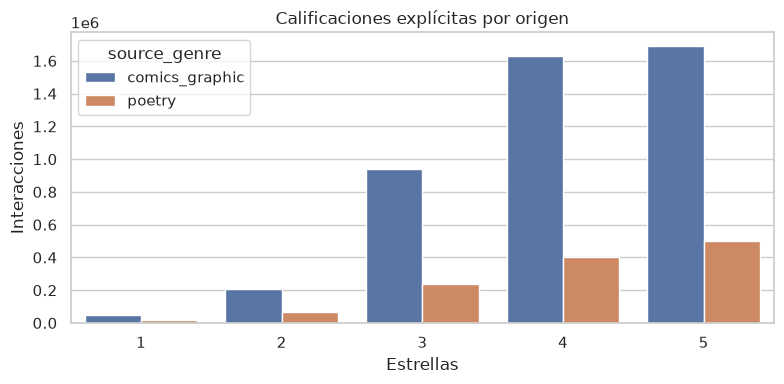

,estado,rating,interacciones
0,Lectura confirmada,1,69228
1,Lectura confirmada,2,273925
2,Lectura confirmada,3,1175359
3,Lectura confirmada,4,2032576
4,Lectura confirmada,5,2189774
5,Lectura confirmada,Sin rating explícito,334456
6,Pendiente/no confirmada,Sin rating explícito,4000408


**Interpretación.** 43.0% de interacciones no tiene rating explícito. Por tanto, `rating=0` no puede etiquetarse como rechazo; la tabla permite evaluar por separado lecturas confirmadas, pendientes y actividad sin calificar al definir relevancia futura.

In [6]:
rating_by_source = q(f"""SELECT s.source_genre, i.explicit_rating AS rating, count(*) AS interacciones
FROM read_parquet('{interactions}') i JOIN read_parquet('{interaction_sources}') s USING(interaction_id)
WHERE i.has_explicit_rating GROUP BY 1, 2 ORDER BY 1, 2""")
plt.figure(figsize=(8, 4)); sns.barplot(data=rating_by_source, x='rating', y='interacciones', hue='source_genre')
plt.title('Calificaciones explícitas por origen'); plt.xlabel('Estrellas'); plt.ylabel('Interacciones'); savefig('06_ratings_by_source.png')
read_rating = q(f"""SELECT CASE WHEN is_read THEN 'Lectura confirmada' ELSE 'Pendiente/no confirmada' END AS estado,
  CASE WHEN has_explicit_rating THEN cast(rating AS VARCHAR) ELSE 'Sin rating explícito' END AS rating, count(*) AS interacciones
FROM read_parquet('{interactions}') GROUP BY 1, 2 ORDER BY 1, 2""")
display(read_rating)
no_rating = int(read_rating.loc[read_rating.rating.eq('Sin rating explícito'), 'interacciones'].sum())
total_interactions = int(read_rating.interacciones.sum())
display(Markdown(f"**Interpretación.** {no_rating / total_interactions:.1%} de interacciones no tiene rating explícito. Por tanto, `rating=0` no puede etiquetarse como rechazo; la tabla permite evaluar por separado lecturas confirmadas, pendientes y actividad sin calificar al definir relevancia futura."))


## 5. Actividad, parejas repetidas y dispersión
Objetivo: caracterizar la cola larga sin una matriz densa. La actividad se grafica hasta p99 en eje logarítmico y las colas se reportan por separado; así los máximos no vuelven ilegible la distribución central.

,umbral_interacciones,pct_usuarios
0,5,48.27
1,10,31.46
2,20,18.77


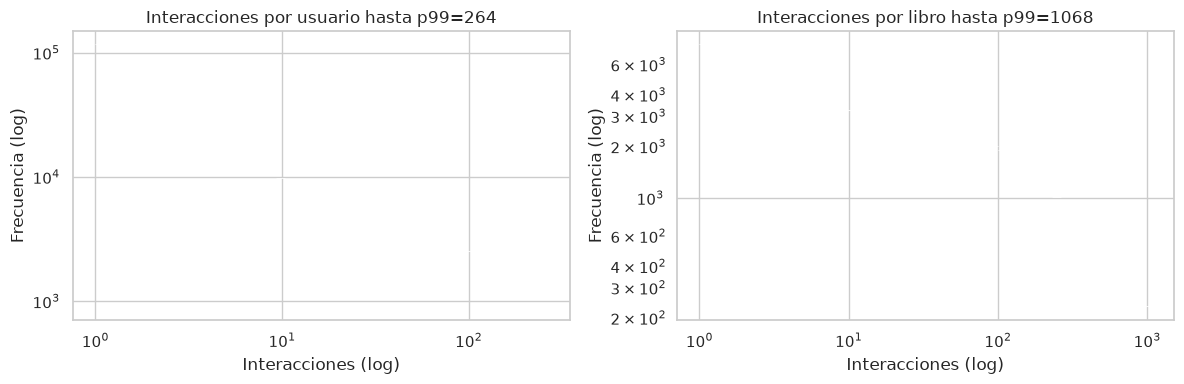

,parejas_unicas,filas,parejas_repetidas,filas_en_parejas_repetidas,densidad_parejas
0,10075726,10075726.0,0.0,0.0,0.00016


**Interpretación.** Solo 48.3% de usuarios alcanza 5 interacciones. La dispersión se calcula con parejas únicas (0.015992%), por lo que no confunde reinteracciones con nuevas aristas usuario-libro. Los mínimos de actividad futuros deberán justificarse contra esta pérdida de cobertura.

In [7]:
user_counts = q(f"SELECT user_id, count(*) AS n FROM read_parquet('{interactions}') GROUP BY 1")
book_counts = q(f"SELECT book_id, count(*) AS n FROM read_parquet('{interactions}') GROUP BY 1")
thresholds = pd.DataFrame({'umbral_interacciones': [5, 10, 20], 'pct_usuarios': [100 * (user_counts.n >= n).mean() for n in [5, 10, 20]]})
display(thresholds.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, frame, label in zip(axes, [user_counts, book_counts], ['usuario', 'libro']):
    limit = frame.n.quantile(.99); visible = frame[frame.n <= limit]
    sns.histplot(visible.n, bins=50, log_scale=(True, True), ax=ax, color='#76b7b2')
    ax.set(title=f'Interacciones por {label} hasta p99={limit:.0f}', xlabel='Interacciones (log)', ylabel='Frecuencia (log)')
savefig('08_activity_distributions.png')
pairs = q(f"""WITH p AS (SELECT user_id, book_id, count(*) AS n FROM read_parquet('{interactions}') GROUP BY 1, 2)
SELECT count(*) AS parejas_unicas, sum(n) AS filas, sum(n > 1) AS parejas_repetidas, sum(CASE WHEN n > 1 THEN n ELSE 0 END) AS filas_en_parejas_repetidas,
  1.0 * count(*) / ((SELECT count(DISTINCT user_id) FROM read_parquet('{interactions}')) * (SELECT count(DISTINCT book_id) FROM read_parquet('{interactions}'))) AS densidad_parejas
FROM p""")
display(pairs)
display(Markdown(f"**Interpretación.** Solo {thresholds.loc[thresholds.umbral_interacciones.eq(5), 'pct_usuarios'].iloc[0]:.1f}% de usuarios alcanza 5 interacciones. La dispersión se calcula con parejas únicas ({pairs.loc[0, 'densidad_parejas']:.6%}), por lo que no confunde reinteracciones con nuevas aristas usuario-libro. Los mínimos de actividad futuros deberán justificarse contra esta pérdida de cobertura."))


## 6. Calidad y distribución temporal de interacciones
Objetivo: evaluar qué fechas pueden respaldar una futura partición cronológica. Se distingue entre fecha ausente, fecha presente no parseable y fecha normalizada correctamente; `date_added` no se interpreta como lectura efectiva.

,interacciones,added_ausente,added_invalida,added_valida,read_ausente,read_invalida,read_valida
0,10075726,0.0,0.0,10075726.0,7391472.0,0.0,2684254.0


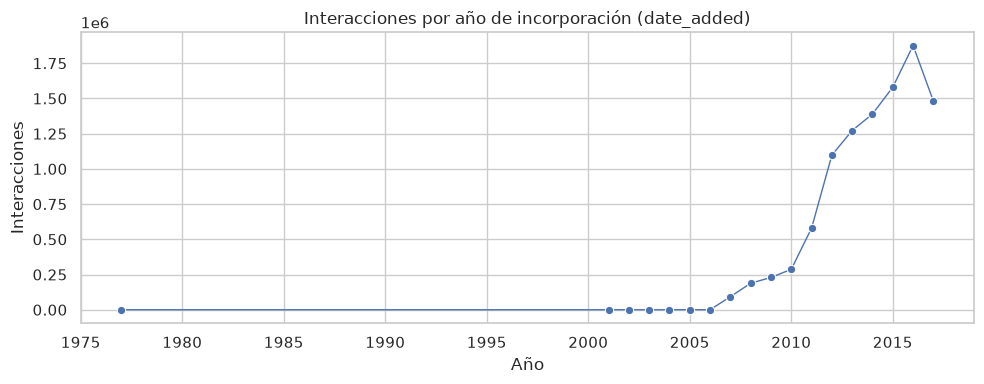

**Interpretación.** `date_added` es parseable para 100.0% de las interacciones. Puede explorarse para un split cronológico, pero no sustituye a `read_at`; la calidad de ambas fechas debe incluirse en el protocolo experimental futuro.

In [8]:
date_quality = q(f"""SELECT
 count(*) AS interacciones,
 sum(date_added_raw IS NULL) AS added_ausente, sum(date_added_raw IS NOT NULL AND date_added_utc IS NULL) AS added_invalida, sum(date_added_utc IS NOT NULL) AS added_valida,
 sum(read_at_raw IS NULL) AS read_ausente, sum(read_at_raw IS NOT NULL AND read_at_utc IS NULL) AS read_invalida, sum(read_at_utc IS NOT NULL) AS read_valida
FROM read_parquet('{interactions}')""")
display(date_quality)
added_years = q(f"SELECT year(date_added_utc) AS anio, count(*) AS interacciones FROM read_parquet('{interactions}') WHERE date_added_utc IS NOT NULL GROUP BY 1 ORDER BY 1")
plt.figure(figsize=(10, 4)); sns.lineplot(data=added_years, x='anio', y='interacciones', marker='o', linewidth=1)
plt.title('Interacciones por año de incorporación (date_added)'); plt.xlabel('Año'); plt.ylabel('Interacciones'); savefig('09_interaction_dates.png')
valid_added = date_quality.loc[0, 'added_valida'] / date_quality.loc[0, 'interacciones']
display(Markdown(f"**Interpretación.** `date_added` es parseable para {valid_added:.1%} de las interacciones. Puede explorarse para un split cronológico, pero no sustituye a `read_at`; la calidad de ambas fechas debe incluirse en el protocolo experimental futuro."))


## 7. Hallazgos y decisiones posteriores
1. Mantener los registros contradictorios de `review_id` fuera de deduplicación automática y cuantificarlos antes de cualquier split.
2. Conservar interacciones sin rating como señal implícita separada, nunca como desagrado.
3. Evaluar umbrales de actividad sobre conectividad y cobertura, dado que la distribución es de cola larga.
4. Excluir las estadísticas globales de popularidad y rating del entrenamiento futuro para evitar fuga; recalcularlas solo con entrenamiento.
5. Usar `date_added` únicamente con la salvedad de que representa incorporación, no lectura, y definir tratamiento de fechas ausentes antes de un split temporal.

Al añadir nuevos géneros, regenere los Parquet y ejecute el notebook completo: las consultas usan las relaciones de procedencia y no fijan una lista de géneros.